# P7.12 — Passa-altas FIR com janela fixa escolhida

*FIR · passa-altas · escolha justificada da janela · Rp muito exigente*

> Notebook gerado de `content/p7_12.py`, a mesma fonte da aplicação DSP Filter Lab e do relatório PDF. Para alterar o texto, edite o conteúdo e rode `tools/run_notebook.sh p7_12`.

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Enunciado original

> *Design a highpass filter using one of the fixed window functions. The specifications are: stopband edge: 0.4π, As = 50 dB; passband edge: 0.6π, Rp = 0.004 dB. Plot the zoomed magnitude response (in dB) of the designed filter in the passband to verify the passband ripple Rp. Do not use the fir1 function.*

Fonte: DTA §2.1 item 4 e §4 (Resolução P7.12); Ingle & Proakis, p. 379.

## 2. O que está sendo pedido


Projetar um **filtro FIR passa-altas** com transição entre $0.4\pi$ e $0.6\pi$, usando **uma das janelas fixas, a escolher**.

- Atenuação de pelo menos $A_s = 50$ dB na rejeição.
- Ondulação de no máximo $R_p = 0.004$ dB na passagem. É uma exigência **muito** rigorosa.

O gráfico pedido é o **zoom da passagem em dB**, para verificar $R_p$. O ponto central do exercício é **justificar a escolha da janela**.

## 3. Dados e especificações

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| Rejeição | $0 \le \omega \le 0.4\pi$ | ■ Dado do enunciado | a ser atenuada |
| Passagem | $0.6\pi \le \omega \le \pi$ | ■ Dado do enunciado | a ser preservada |
| $A_s$ | 50 dB | ■ Dado do enunciado | atenuação mínima |
| $R_p$ | 0.004 dB | ■ Dado do enunciado | ondulação máxima na passagem |
| Método | uma janela fixa, sem `fir1` | ■ Dado do enunciado | a janela fica a critério do projetista |


Converter $R_p$ em tolerância linear (passo 1) mostra por que este exercício é diferente dos anteriores: quem decide a janela é a ondulação da passagem, não a atenuação.

## 4. Fundamentação teórica


**Ondulações iguais nas duas faixas.** No método da janela, a ondulação da passagem ($\delta_1$) e a da rejeição ($\delta_2$) vêm dos mesmos lóbulos laterais e saem com amplitudes semelhantes. Uma exigência rigorosa em **qualquer** das faixas obriga a usar uma janela de lóbulos baixos.

**A janela fixa a ondulação; $M$ fixa a transição.** Aumentar $M$ estreita a transição, mas **não reduz** os lóbulos laterais, que são uma propriedade da forma da janela. Se uma janela não atende $R_p$ com um comprimento, não atende com nenhum.

**Passa-altas e paridade.** O passa-altas precisa de ganho 1 em $\omega = \pi$, então só o Tipo 1 serve: $M$ ímpar.

**Candidatas** (Tabela 7.1, conforme o DTA): Hann (≈ 44 dB, $6.2\pi/M$), Hamming (≈ 53 dB, $6.6\pi/M$), Blackman (≈ 74 dB, $11\pi/M$).


#### Aprofundamento: Como R_p vira uma tolerância linear?


Por definição, $R_p = -20\log_{10}\frac{1-\delta_1}{1+\delta_1}$. Isolando $\delta_1$:

$$\delta_1 = \frac{10^{R_p/20} - 1}{10^{R_p/20} + 1}.$$

Com $R_p = 0.004$ dB, $\delta_1 \approx 2.303\times10^{-4}$. Como a janela produz $\delta_2 \approx \delta_1$, isso equivale a exigir lóbulos laterais em torno de $-20\log_{10}\delta_1 \approx 72.8$ dB, bem mais que os 50 dB pedidos para a rejeição.

## 5. Equações e variáveis

**(1) Ondulação linear da passagem** · *DTA §3.1.A*

$$
\delta_1 = \frac{10^{R_p/20}-1}{10^{R_p/20}+1}
$$

Inversão da definição de $R_p$.

| Símbolo | Significado |
|---|---|
| $\delta_1$ | desvio máximo do ganho em torno de 1 |

**(2) Comprimento pela Tabela 7.1 (Blackman)** · *DTA §3.1.C*

$$
M = \left\lceil \frac{11\pi}{\Delta\omega} \right\rceil + 1
$$



**(3) Janela de Blackman** · *DTA §3.1.C*

$$
w(n) = 0.42 - 0.5\cos\left(\frac{2\pi n}{M-1}\right) + 0.08\cos\left(\frac{4\pi n}{M-1}\right)
$$



**(4) Resposta ideal do passa-altas** · *DTA §3.1.E*

$$
h_d(n) = \delta(n-\alpha) - \frac{\sin[\omega_c(n-\alpha)]}{\pi(n-\alpha)}
$$

Passa-tudo menos passa-baixas.

| Símbolo | Significado |
|---|---|
| $\omega_c$ | corte, no meio da transição |

**(5) Filtro projetado** · *DTA §3.1*

$$
h(n) = h_d(n)\,w(n)
$$

## 6. Resolução passo a passo

### Passo 1 — Traduzir R_p em tolerância linear

Para comparar com o que cada janela consegue (ver aprofundamento).

$$
\delta_1 = \frac{10^{0.004/20}-1}{10^{0.004/20}+1} = 2.303\times10^{-4} \;\Rightarrow\; -20\log_{10}\delta_1 \approx 72.8\ \text{dB}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\delta_1$ | $2.303\times10^{-4}$ | ∑ Valor calculado | tolerância linear na passagem |

### Passo 2 — Transição, corte e paridade

Uma só transição. O passa-altas exige $M$ ímpar.

$$
\Delta\omega = 0.6\pi - 0.4\pi = 0.2\pi, \qquad \omega_c = \frac{0.4\pi + 0.6\pi}{2} = 0.5\pi
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\Delta\omega$ | $0.2\pi$ | ∑ Valor calculado | largura de transição |
| $\omega_c$ | $0.5\pi$ | ∑ Valor calculado | corte |

### Passo 3 — Avaliar cada janela fixa

Cada candidata é testada primeiro pelo $A_s$ nominal e depois pela **medição** do filtro projetado com o $M$ da Tabela 7.1:

| Janela | $A_s$ tabela | $M$ | $R_p$ medido (dB) | $A_s$ medido (dB) | resultado |
|---|---|---|---|---|---|
| Hann | 44 dB | — | — | — | descartada: $A_s$ nominal < exigido |
| Hamming | 53 dB | 35 | 0.04013 | 51.98 | não atende ($R_p$) |
| Blackman | 74 dB | 57 | 0.00296 | 75.25 | **atende** |

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| Hamming | $R_p$ = 0.0401 dB | ● Resultado obtido | atende $A_s$, mas $R_p$ fica ~10× acima do limite |

### Passo 4 — Confirmar que aumentar M não salva a Hamming

Se o problema fosse o comprimento, mais coeficientes resolveriam. A medição mostra que não resolvem:

| $M$ | $R_p$ Hamming (dB) |
|---|---|
| 35 | 0.0401 |
| 45 | 0.0286 |
| 55 | 0.0318 |
| 65 | 0.0283 |
| 75 | 0.0300 |
| 85 | 0.0271 |
| 95 | 0.0279 |

$$
R_{p,\text{Hamming}} \in [0.027,\ 0.040]\ \text{dB} \;>\; 0.004\ \text{dB} \quad \text{para } M = 35\ldots95
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| conclusão | trocar de janela | ✓ Critério de validação | a ondulação é da forma da janela |

### Passo 5 — Escolher a Blackman e calcular o comprimento

É a única com lóbulos baixos o suficiente (nominal ≈ 74 dB, coerente com os ≈ 73 dB do passo 1).

$$
M = \left\lceil \frac{11\pi}{0.2\pi} \right\rceil + 1 = 55 + 1 = 56 \;\xrightarrow{M\ \text{ímpar}}\; 57, \qquad \alpha = 28
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| janela | Blackman | ◆ Parâmetro escolhido | justificada pelos passos 1, 3 e 4 |
| $M$ | 57 | ∑ Valor calculado | 56 pela tabela, +1 pela paridade |

> ⚠️ O DTA escreve $\lceil 11\pi/0.2\pi\rceil + 1 = 57$. A conta dá 56; o 57 vem da regra de paridade (item V3 da errata).

### Passo 6 — Construir o filtro e medir

Medição em 20001 frequências, com as bordas.

$$
R_p = 0.00296\ \text{dB} \le 0.004, \qquad A_s = 75.25\ \text{dB} \ge 50
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $R_p$ | 0.00296 dB | ● Resultado obtido | folga de 0.00104 dB |
| $A_s$ | 75.25 dB | ● Resultado obtido | folga de 25.3 dB |

### Passo 7 — Observar o comprimento mínimo com Blackman (complementar)

O enunciado não pede o mínimo. Mesmo assim:

| $M$ | $R_p$ (dB) | $A_s$ (dB) | atende? |
|---|---|---|---|
| 51 | 0.01008 | 60.09 | ✗ não |
| 53 | 0.00610 | 65.52 | ✗ não |
| 55 | 0.00393 | 71.03 | ✓ sim |
| 57 | 0.00296 | 75.25 | ✓ sim |
| 59 | 0.00260 | 75.32 | ✓ sim |

$$
M = 55:\ R_p = 0.00393\ \text{dB}\ (\text{folga de } 7.3\times10^{-5}\ \text{dB})
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $M = 55$ | também atende | ● Resultado obtido | com margem desprezível |

## 7. Implementação computacional


1. **Candidatas** (`evaluate_candidates`): para cada janela fixa, descarta pelo $A_s$ nominal ou projeta com o $M$ da tabela e mede $R_p$ e $A_s$.
2. **Escolha** (`design`): a primeira janela, na ordem de comprimento crescente, que atende às duas exigências medidas.
3. **Medição** (`validate_fir_db`): $R_p$ e $A_s$ nas grades de 501 e 20001 pontos com as bordas.


| Função | O que faz |
|---|---|
| `exercises.p7_12.evaluate_candidates` | Passo 3: avalia Hann, Hamming e Blackman |
| `exercises.p7_12.design` | Passo 5: escolhe a primeira janela que atende |
| `dsp_av2.fir.design.design_fixed_window` | Projeto com janela fixa (com ajuste de paridade) |
| `dsp_av2.validation.validate_fir_db` | Passo 6: mede Rp e As |

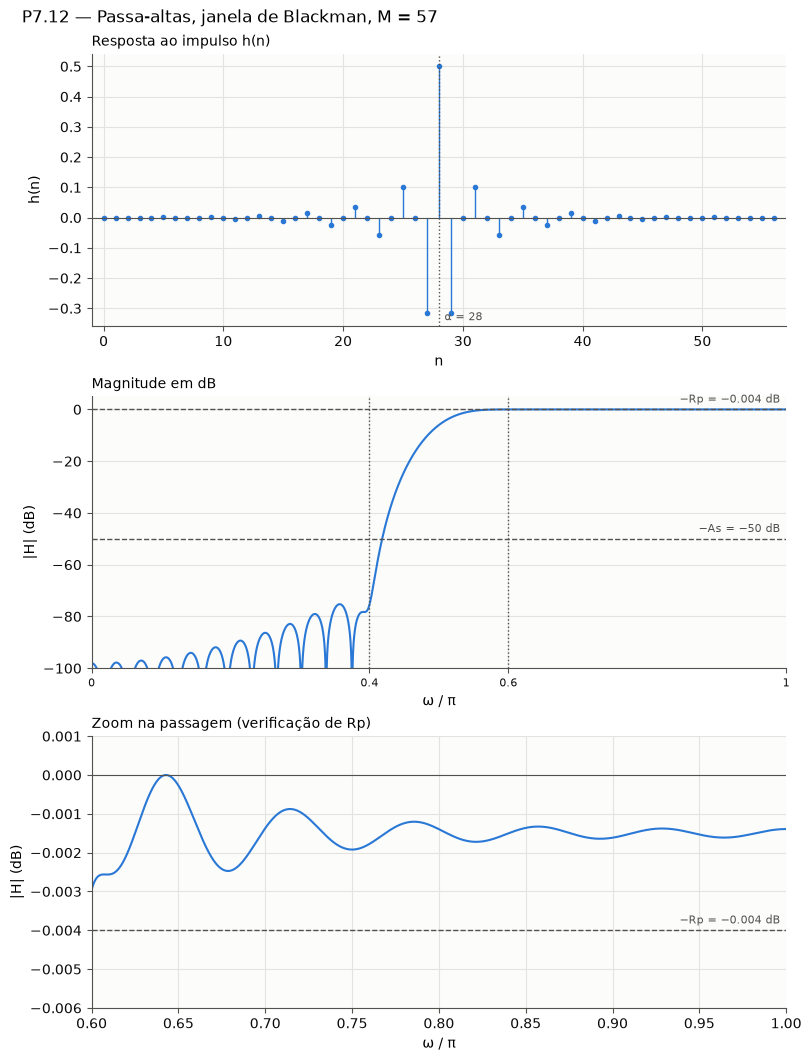

In [2]:
from content import p7_12 as content_mod
objs = content_mod.objects()
import matplotlib.pyplot as plt
from exercises import p7_12
fig = p7_12.plot(objs['final'])
plt.show()

## 8. Gráficos e interpretação

### Zoom na passagem: o gráfico pedido


A ondulação na passagem é de milésimos de dB: o máximo desvio é 0.00296 dB, abaixo da linha de $-0.004$ dB. As oscilações diminuem à medida que $\omega$ se afasta da borda $0.6\pi$.


### Resposta ao impulso $h(n)$


Simétrica em torno de $n = 28$, com o coeficiente central próximo de $1 - \omega_c/\pi = 0.5$ (passa-tudo menos passa-baixas).


### Magnitude em dB


A rejeição chega a −75.3 dB, muito além dos 50 dB exigidos. É o efeito colateral de escolher a janela pela exigência de $R_p$.


### $R_p$ da Hamming em função de $M$


Para todos os comprimentos testados, a Hamming fica entre 0.027 e 0.040 dB, sempre acima do limite de 0.004 dB. A ondulação não depende do comprimento.

## 9. Verificação das especificações


Critério do livro (dB normalizado, grades com as bordas). O limite decisivo é $R_p$.

In [3]:
rep = objs.get('final_report') or objs.get('report')
print(rep)

Validação P7.12 (Tipo 1 de fase linear)
  [OK  ] Rp [dB] (grade livro): 0.0030 <= 0.0040  (folga +0.0010)
  [OK  ] As [dB] (grade livro): 75.2774 >= 50.0000  (folga +25.2774)
  [OK  ] Rp [dB] (grade densa): 0.0030 <= 0.0040  (folga +0.0010)
  [OK  ] As [dB] (grade densa): 75.2530 >= 50.0000  (folga +25.2530)
  Resultado: ATENDE à especificação


## 10. Conclusão técnica


- A exigência $R_p = 0.004$ dB equivale a lóbulos de ≈ 73 dB, e é ela que define a janela.
- Hann: descartada pelo $A_s$ nominal. Hamming: atende $A_s$, mas $R_p$ fica entre 0.027 e 0.040 dB para qualquer $M$.
- **Blackman com $M = 57$** (Tipo 1, $\alpha = 28$): $R_p = 0.00296$ dB e $A_s = 75.25$ dB. **Atende.**
- $M = 55$ também atenderia, com margem desprezível. A conta da tabela dá 56; o 57 vem da paridade (V3).